# VaR 99% de 1 dia por Monte Carlo e quasi-Monte Carlo

Mede tau_c(N, K), o tempo que o método clássico leva para entregar o VaR de uma carteira de opções sobre N ações com um erro-alvo fixo (etapas 1 e 3 da metodologia em `artigo.md`). O resultado vai para `../dados/tau_c.csv`.

**Carteira.** Definida em `carteira.py`, a mesma do `2_backtest.ipynb`: por ação, 5 straddles vendidos (K = 10 opções) com strikes de 90% a 110% do preço atual, vencimento de 3 meses e hedge de delta na própria ação.

**Erro-alvo.** O desvio padrão do VaR estimado, entre sementes, é no máximo `EPS_REL` vezes o VaR. Para cada N e método, o erro é medido com 50 sementes em três valores de M, e a reta log(erro) x log(M) dá o M necessário. O Monte Carlo deve ter inclinação perto de -1/2; o quasi-Monte Carlo, mais íngreme. tau_c é o tempo de um cálculo com esse M.

In [1]:
import csv, platform, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from carteira import K, calcular_var, montar_carteira   # carteira e precificação em carteira.py

EPS_REL = 0.01                          # erro-alvo relativo
NS = [2**k for k in range(10)]          # 1 a 512 ações
MS_ERRO = [2**10, 2**12, 2**14]         # cenários usados para medir a lei do erro
SEMENTES = range(50)
METODOS = ["mc", "qmc"]

# hardware documentado (etapa 3 da metodologia)
print(platform.platform(), platform.processor(), "| numpy", np.__version__)

macOS-27.2-arm64-arm-64bit-Mach-O arm | numpy 2.5.4


In [2]:
for metodo in METODOS:
    print(metodo, calcular_var(2, 2**14, metodo, 0, montar_carteira(2)))

mc 2.543752598907115
qmc 2.5852250357454984


## Lei do erro em função de M

In [3]:
erro = {}
t0 = time.time()
for N in NS:
    carteira = montar_carteira(N)
    for metodo in METODOS:
        for M in MS_ERRO:
            v = [calcular_var(N, M, metodo, s, carteira) for s in SEMENTES]
            erro[metodo, N, M] = np.std(v, ddof=1) / np.mean(v)
    print(f"N={N} pronto, {time.time() - t0:.0f} s")


def lei_do_erro(metodo, N):
    """Inclinação b e intercepto a de log(erro) = a + b log(M)."""
    return np.polyfit(np.log(MS_ERRO), np.log([erro[metodo, N, M] for M in MS_ERRO]), 1)

N=1 pronto, 0 s


N=2 pronto, 1 s


N=4 pronto, 2 s


N=8 pronto, 5 s


N=16 pronto, 10 s


N=32 pronto, 21 s


N=64 pronto, 43 s


N=128 pronto, 86 s


N=256 pronto, 172 s


N=512 pronto, 345 s


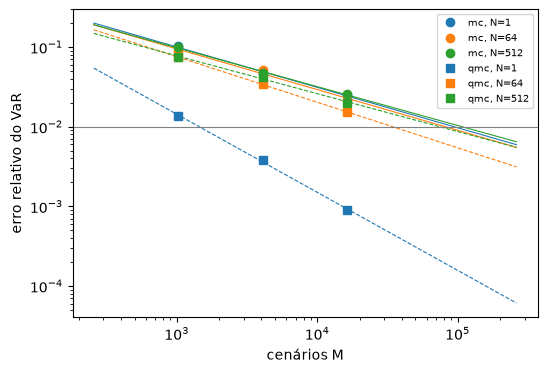

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
grade = np.array([2**8, 2**18])
for metodo, marca in (("mc", "o"), ("qmc", "s")):
    for N, cor in ((1, "C0"), (64, "C1"), (512, "C2")):
        b, a = lei_do_erro(metodo, N)
        ax.loglog(MS_ERRO, [erro[metodo, N, M] for M in MS_ERRO], marca, color=cor, label=f"{metodo}, N={N}")
        ax.loglog(grade, np.exp(a) * grade**b, "-" if metodo == "mc" else "--", color=cor, lw=0.8)
ax.axhline(EPS_REL, color="gray", lw=0.8)
ax.set(xlabel="cenários M", ylabel="erro relativo do VaR")
ax.legend(fontsize=7)
Path("../figuras").mkdir(exist_ok=True)
plt.savefig("../figuras/var_classico_erro.png", dpi=150)
plt.show()

## tau_c(N, K)

M necessário: o M da lei do erro que atinge `EPS_REL`, arredondado para a potência de 2 acima (a sequência de Sobol exige potência de 2; o Monte Carlo usa o mesmo arredondamento para a comparação ser justa). tau_c é a mediana de 3 execuções com esse M, no hardware impresso no início.

In [5]:
linhas = []
for N in NS:
    carteira = montar_carteira(N)
    for metodo in METODOS:
        b, a = lei_do_erro(metodo, N)
        M = 2 ** int(np.ceil((np.log(EPS_REL) - a) / b / np.log(2)))
        tempos = []
        for s in range(3):
            t0 = time.perf_counter()
            calcular_var(N, M, metodo, s, carteira)
            tempos.append(time.perf_counter() - t0)
        linhas.append((N, K, metodo, M, round(b, 3), float(np.median(tempos))))

Path("../dados").mkdir(exist_ok=True)
with open("../dados/tau_c.csv", "w", newline="") as f:
    csv.writer(f).writerows([("N", "K", "metodo", "M", "inclinacao_erro", "tau_c_s"), *linhas])

print("N    K  metodo        M  inclinação  tau_c (s)")
for N, K_, metodo, M, b, t in linhas:
    print(f"{N:<4} {K_:<2} {metodo:<5} {M:>9}  {b:>10}  {t:9.4f}")

N    K  metodo        M  inclinação  tau_c (s)
1    10 mc       131072      -0.507     0.0213
1    10 qmc        2048       -0.98     0.0005
2    10 mc       131072      -0.558     0.0406
2    10 qmc        8192      -0.818     0.0026
4    10 mc       131072      -0.505     0.0788
4    10 qmc       32768      -0.521     0.0195
8    10 mc       131072      -0.535     0.1565
8    10 qmc       65536      -0.488     0.0797
16   10 mc       131072      -0.439     0.3120
16   10 qmc       65536        -0.5     0.1583
32   10 mc       262144      -0.419     1.2479
32   10 qmc       65536       -0.49     0.3201
64   10 mc       131072      -0.511     1.2546
64   10 qmc       65536      -0.572     0.6415
128  10 mc       131072      -0.497     2.5103
128  10 qmc       65536      -0.573     1.2912
256  10 mc       131072      -0.531     5.0407
256  10 qmc       65536      -0.518     2.5893
512  10 mc       131072      -0.488    10.3180
512  10 qmc      131072      -0.475    10.5766


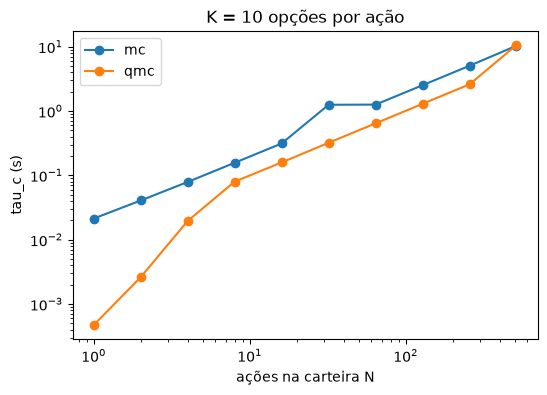

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
for metodo in METODOS:
    pts = [(n, t) for n, _, m, _, _, t in linhas if m == metodo]
    ax.loglog(*zip(*pts), "o-", label=metodo)
ax.set(xlabel="ações na carteira N", ylabel="tau_c (s)", title=f"K = {K} opções por ação")
ax.legend()
plt.savefig("../figuras/var_classico_tau.png", dpi=150)
plt.show()

## O que observar

- A inclinação do Monte Carlo deve ficar perto de -1/2, que é o 1/eps^2 em número de cenários. A estimação quântica de amplitude é comparada contra essa curva e contra a do quasi-Monte Carlo.
- A vantagem do quasi-Monte Carlo tende a diminuir quando N cresce.
- Os dois lados rodam sem fila nem rede, então tau_c(N, K), como tau_q(N), mede só o cálculo.
- **Limite desta referência clássica.** Aqui cada cenário reavalia as N x K opções por Black-Scholes. Como as opções de uma ação dependem só do preço dela, uma tabela de reavaliação por ação (valor da carteira daquela ação numa grade de preços, interpolado em cada cenário) deixaria tau_c quase independente de K. A reavaliação completa representa carteiras cujas opções não têm fórmula fechada, como americanas e exóticas, e essa escolha precisa estar declarada no artigo.